### Stage 3 — Exploratory Data Analysis

Investigate the distribution of:

- Property prices.
- Property sizes.
- Available property characteristics.
- Geographic locations.

Use appropriate visualizations, including histograms, box plots, scatter plots, and geographical visualizations where appropriate.

### Stage 4 — Property Size Analysis

Investigate whether larger properties tend to have higher listing prices.

Potential techniques:

- Scatter plots of property size against price.
- Pearson correlation for linear association.
- Spearman correlation for rank-based monotonic association.
- Comparison of price distributions across size groups.
- Price-per-square-meter analysis, where possible.

In [2]:
import pandas as pd

# Define the path to the clean CSV file saved in Notebook 1
data_path = r"C:\Dell\Project Github\mexican-real-estate-analysis\data\processed\mexico-real-combined-clean.csv"

# Load the data
df = pd.read_csv(data_path)

# Verify the load
print(f"Dimensions: {df.shape[0]} rows and {df.shape[1]} columns.")
print(df.info())
df.head()

Dimensions: 1736 rows and 6 columns.
<class 'pandas.DataFrame'>
RangeIndex: 1736 entries, 0 to 1735
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  1736 non-null   str    
 1   state          1736 non-null   str    
 2   lat            1736 non-null   float64
 3   lon            1736 non-null   float64
 4   area_m2        1736 non-null   float64
 5   price_usd      1736 non-null   float64
dtypes: float64(4), str(2)
memory usage: 81.5 KB
None


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37


#### 2. Univariate Analysis: Understanding One Variable at a Time

Before we look for relationships between variables, we must understand each variable individually. This is called **univariate analysis** — analysis of one variable at a time.

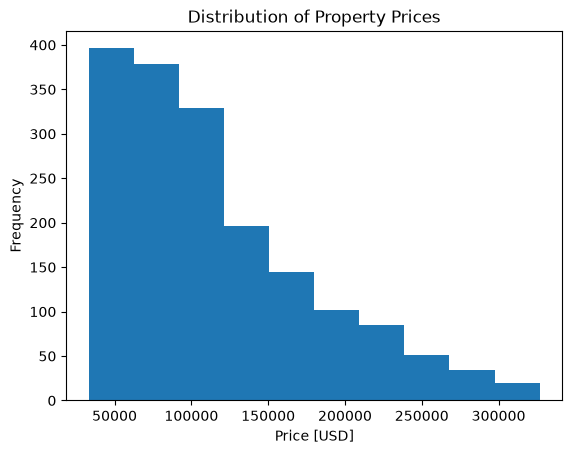

In [ ]:
# Price Distribution

# import matplotlib
import matplotlib.pyplot as plt

# Create a histogram for price
fig, ax = plt.subplots()

# Create a histogram for price_usd
ax.hist(df["price_usd"])

# Add x-axis label, y-axis label & title
ax.set_xlabel("Price [USD]")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Property Prices"); # The semi-colon is added to suppress some ugly text and just gives us the graphic.

>📊 Reading the price_usd histogram — right skew in housing data
>
>Shape: The distribution is strongly right-skewed (positively skewed). The tallest bars are on the left — most properties are priced between 30,000 and 130,000. The distribution then tapers off slowly to the right, with a long thin tail of expensive properties extending to 300,000+.
>
>"The tail tells the tale": In statistics, skewness is measured by which side of the distribution has the longer tail. A right tail means a small number of high-value observations are pulling the mean above the median.
>
>Why right skew is the norm in housing markets: Property prices have a natural lower bound (no property costs zero or less) but effectively no upper bound (a luxury property can cost 100x the median). This asymmetry guarantees a right-skewed distribution in almost every real estate market.
>
>Mean vs median in this histogram:
>
>The median (the 50th percentile) sits roughly at the histogram's peak — around 95,000-100,000.
>The mean is pulled rightward by the tail — roughly 115,000.
>The 15,000-20,000 gap between them is the price of ignoring skewness.

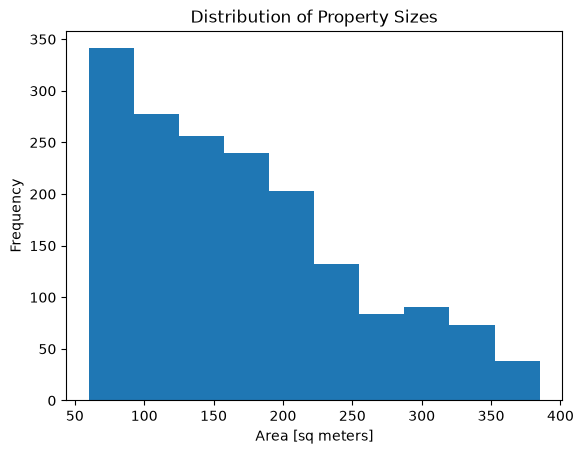

In [ ]:
# Property Size

# Create a histogram for area_m2
fig, ax = plt.subplots()

# Use Matplotlib to create histogram of "area_m2"
ax.hist(df["area_m2"])

# Add x-axis label, y-axis label & title
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Property Sizes");

>📊 Reading the area_m2 histogram — size distribution and what it implies
>
>Shape: Also right-skewed, but for a different reason. Most properties in the dataset are apartments or smaller houses (50–150 m²), with a long tail of larger properties (mansions or commercial listings that crept into the dataset).

>Comparing the two histograms:

>Variable	Peak (mode)	Right tail	Implication
price_usd	~60,000–80,000	Long — extends to the most expensive listing	A few luxury properties inflate the mean
area_m2	~80–120 m²	Long — extends to the largest listing	A few large properties inflate the mean
Why both are right-skewed: Both price and area have a physical lower bound (a property must have positive size and a positive price) but no mathematical upper bound. Any variable with a hard floor but no ceiling tends to be right-skewed.

>What this means for size-price analysis: If we correlate raw area_m2 with raw price_usd, the handful of extreme outliers (a 800 m² mansion at $300,000) will dominate the relationship and misrepresent the typical market. We will need to remove these before any scatterplot or correlation analysis 

#### 3. Bivariate Analysis: Categorical vs. Numerical

Now that we understand each variable individually, we move to **bivariate analysis** — studying the relationship between two variables simultaneously. We start by comparing a numerical variable (price_usd) against a categorical variable (property_type, state). The right tool for this is the boxplot.

C:\Users\Dell\AppData\Local\Temp\ipykernel_30424\3605743836.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data_by_type, tick_labels=prop_types, vert=False)


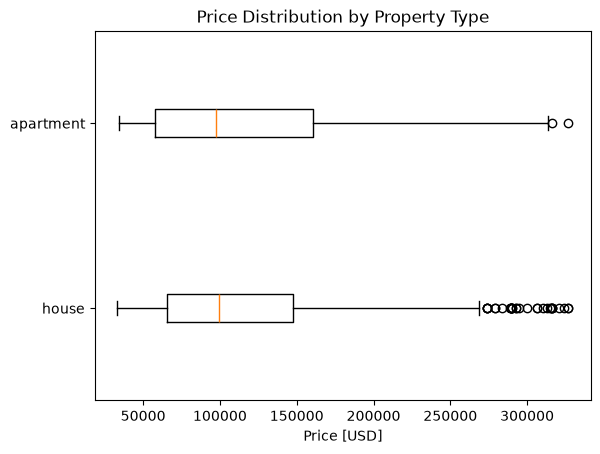

In [5]:
# 1. Get the unique category names on the column "property_type"
prop_types = df["property_type"].unique()

# 2. Prepare the data: Create a list of price arrays, one for each type
data_by_type = [df[df["property_type"] == label]["price_usd"] for label in prop_types]

# 3. Plot
fig, ax = plt.subplots()

# Pass the data list and the labels list
ax.boxplot(data_by_type, tick_labels=prop_types, vert=False)

ax.set_title("Price Distribution by Property Type")
ax.set_xlabel("Price [USD]")


plt.show() # plt.show() acts as the semi-colon, to suppress some ugly text and just give us the graphic.

📊 Reading the property-type boxplot — what the five-number summary reveals

Apply the anatomy from above:

Houses:

Read the median line and the two box edges off your own plot: they give you the typical house price and the range covered by the middle 50% of listings.
Notice the string of outlier dots on the right — expensive houses extending well past the upper fence. These are the luxury single-family homes that drive the right skew we saw in the histogram.
Apartments:

The median line sits close to the one for houses, confirming that the typical price for both property types is similar.
The outlier tail is smaller: fewer dots sit beyond the upper fence.

C:\Users\Dell\AppData\Local\Temp\ipykernel_30424\81081373.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data_by_state, tick_labels=selected_states, vert=False)


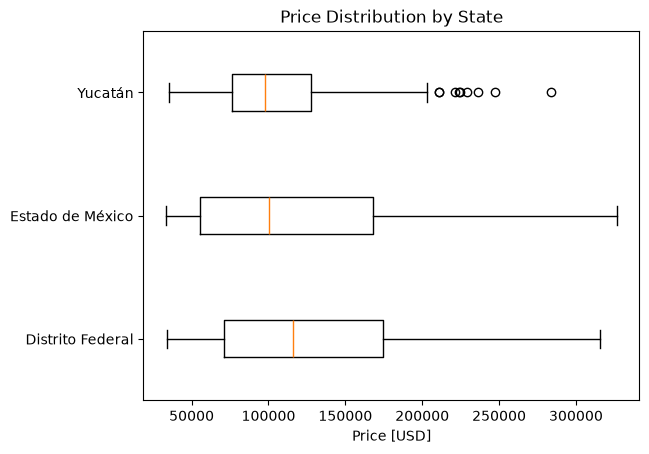

In [6]:
# 1. Define your selected states
selected_states = (
    df["state"]
    .value_counts()
    .head(3)
    .index.tolist()
)
# 2. Prepare the data
data_by_state = [df[df["state"] == state]["price_usd"] for state in selected_states]

# 3. Plot
fig, ax = plt.subplots()

# FIX: Use 'tick_labels' instead of 'labels'
ax.boxplot(data_by_state, tick_labels=selected_states, vert=False)

ax.set_title("Price Distribution by State")
ax.set_xlabel("Price [USD]")
plt.show()

> 📊 **Reading the states boxplot — location as a price driver**
>
> Three states, three very different stories:
>
> **Distrito Federal:**
> - The highest median of the three — Mexico's capital commands a premium.
> - A long right whisker: the ordinary market reaches well above the median, which
>   is what you expect from a market running from modest apartments to premium
>   penthouses.
>
> **Estado de México:**
> - A lower median than Distrito Federal but a comparable upper range — the long
>   right whisker captures high-value suburban properties close to the capital.
>
> **Yucatán:**
> - The lowest median and the narrowest box — the most affordable and the most
>   consistent market. Most listings are similarly priced.
> - A visible chain of outlier dots to the right — a distinct luxury segment
>   (resort-style properties?) that lives well outside the main market.
>
> **Compare the box widths yourself.** The state with the widest box is the one whose
> middle 50% of prices covers the largest range, and it is *not* necessarily the one
> with the highest median. Rank the three boxes by width on your own plot before
> reading on.
>
> ⚠️ **A long whisker and a trail of outlier dots are separate features, and a
> group can show one without the other.** The whisker reaches the last observation
> inside the 1.5 × IQR fence, so a wide box pushes that fence outward and absorbs
> values that a narrower box would have flagged as dots. Do not assume that the
> state with the most expensive properties is the one showing the most dots.
>
> **What this bivariate visualization proves:**
> Even without any formal statistics, the boxplot shows that **location matters**.
> Two properties with the same square footage — one in Distrito Federal, one in
> Yucatán — would likely sell at very different prices. This is the "location
>

#### 4. Bivariate Analysis: Numerical vs. Numerical
The core of our research question is the relationship between **size and price**. Does a bigger property always cost more? Is the relationship consistent, or does it vary by location?

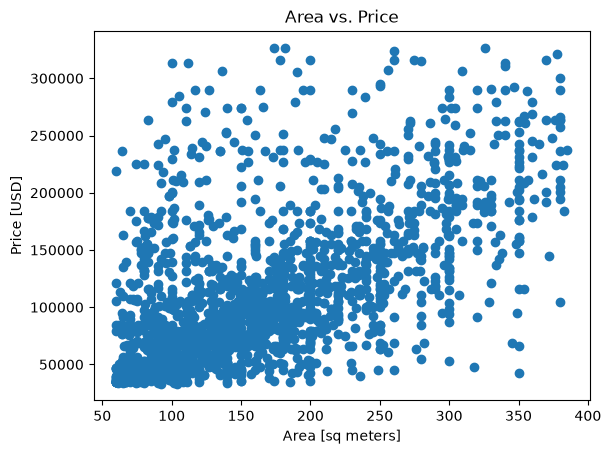

In [7]:
# 1. Create the Figure and Axes objects
fig, ax = plt.subplots()

# 2. Plot on the specific axes object
ax.scatter(x=df["area_m2"], y=df["price_usd"])

# 3. Set labels and title (Note the "set_" prefix)
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Area vs. Price")

plt.show()

> 📊 **Reading the raw scatterplot — compression from outliers**
>
> Look at where the points sit. Most of them crowd toward the lower left, while a
> thinner tail of larger and more expensive properties stretches to the right and
> upward. This is the signature of outliers **compressing the visualization**.
>
> **What "compression" means:** matplotlib scales each axis to the full range of the
> column, so the largest listing in the file sets the x-axis limit for every other
> point. The wider the gap between the largest value and the typical one, the more
> the dense region gets squeezed into a corner and the harder it becomes to read the
> relationship inside it.
>
> ⚠️ **How strong this effect is depends entirely on the tail of your own data.**
> Compare the axis limits against the range where the bulk of the points sit. If the
> largest listing is only moderately above the typical one, the compression will be
> mild and the cleaned plot in the next section will differ from this one in a subtle
> way rather than a dramatic one. Judge it by the axis limits, not by first
> impression.
>
> **What we cannot tell from this plot:**
> - Whether the relationship is linear or curved (the compression hides it)
> - How strong the relationship is (the main cluster is one indistinct blob)
> - Whether the slope is consistent across different price ranges
>

#### 4.2 Handling Outliers: Quantile-Based Filtering

Original: 1736 rows
Cleaned: 1365 rows
Removed: 371 rows


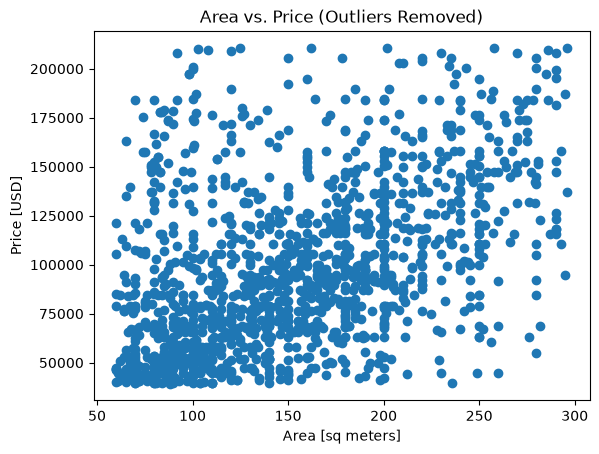

In [ ]:
# Define cutoff percentages
lower_cut = 0.05  # Remove bottom 5%
upper_cut = 0.90  # Keep up to 90th percentile

# Filter the data
df_clean = (
    df[
        (df["price_usd"] > df["price_usd"].quantile(lower_cut)) &
        (df["price_usd"] < df["price_usd"].quantile(upper_cut)) &
        (df["area_m2"] < df["area_m2"].quantile(upper_cut)) # <-- Large area outliers also skew the scatter plot
    ]
)

# Show what changed
print(f"Original: {len(df)} rows")
print(f"Cleaned: {len(df_clean)} rows")
print(f"Removed: {len(df) - len(df_clean)} rows")

# Plot
fig, ax = plt.subplots()
ax.scatter(df_clean["area_m2"], df_clean["price_usd"])
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Area vs. Price (Outliers Removed)")
plt.show()

> 📊 **After outlier removal — reading the improved scatterplot**
>
> The scatterplot should now show a cloud of points with an upward slope, spread
> more evenly across the plot area.
>
> **What changed:** both axes now stop at the quantile cutoffs rather than at the
> extremes of the file, so the same points occupy more of the figure. Put the two
> plots side by side and compare their axis limits: that difference *is* the effect,
> and it can be modest if the tail of your data was not very long to begin with. The
> printed row counts above tell you exactly how many listings were removed.
>
> **What the cleaned scatterplot reveals:**
> - **Positive relationship:** as area increases, price tends to increase.
> - **Significant scatter:** the cloud is wide, not narrow. Pick any area on the
>   x-axis and look at the vertical spread of prices above it: properties of the same
>   size sell across a broad range. This tells us that area *alone* does not fully
>   explain price. Something else matters (location? property type?).
> - **No obvious curve:** the relationship looks roughly linear in this range, which
>   makes Pearson correlation (Lesson 3) an appropriate measure.
>
> **The three things we accomplished by filtering:**
> 1. **Removed noise** — bottom 5% likely contains data errors (implausibly cheap
>    properties); top 10% are luxury outliers that distort the trend.
> 2. **Revealed the pattern** — the main market cluster is now visible and readable.
> 3. **Prepared for modeling** — any future regression model will learn from the
>    "typical" market rather than being pulled by extreme values.

#### 4.3 Visualizing the Trend: Seaborn's regplot
Matplotlib's scatter shows the points; it does not fit a line. We need a regression line — the line of best fit that summarizes the average relationship between x and y. Seaborn makes this effortless with sns.regplot().

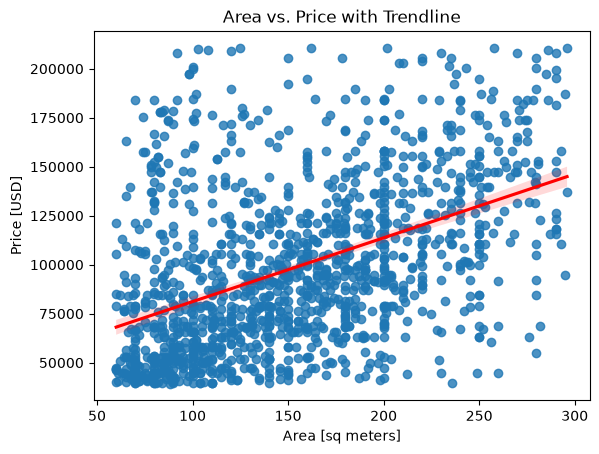

In [14]:
import seaborn as sns

# Create figure and axis explicitly
fig, ax = plt.subplots()

# Use Seaborn to plot scatter + trendline
sns.regplot(
    data=df_clean,
    x="area_m2",
    y="price_usd",
    line_kws={"color": "red"},  # Make the line distinct
    ax=ax  # Pass the axis to seaborn
)

ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Area vs. Price with Trendline")
plt.show()

> 📊 **Reading the `sns.regplot` output — slope, confidence band, and heteroscedasticity**
>
> **The red line (regression line):**
> The line of best fit slopes upward — confirming a positive relationship between
> area and price. As property size increases, price tends to increase.
>
> **The shaded band (confidence interval):**
> The shaded region around the line is the 95% confidence band. It shows where the
> "true" regression line likely falls, given the sample of data we have. A **narrow
> band** means the line is precisely estimated — there is little uncertainty about
> the slope. A **wide band** means high uncertainty.
>
> For this dataset, the band is wide — especially at the high end of the x-axis.
> This is telling you that the regression line's position is not very certain for
> large properties, because there are fewer of them and they are more variable.
>
> **Heteroscedasticity:**
> Notice that the spread of the points *increases* as area increases. At 50 m²,
> prices cluster tightly. At 200 m², prices span a much wider range. This pattern
> — where the variance of the outcome increases with the predictor — is called
> **heteroscedasticity** (Greek for "different scatter"). It is extremely common
> in real estate data because large properties are more heterogeneous (a 300 m²
> property could be a modest house in a cheap area or a luxury villa in an expensive one).
>
> **Heteroscedasticity is not a problem here**, because we are not yet running a
> formal regression model. But it is a useful observation: it tells us that area
> is a *better* predictor of price for small properties than for large ones.
>
> **What the slope value tells us:**
> The slope of the line is approximately the average additional price per additional
> square meter. If the slope is roughly 700/m², then in the typical market, one
> extra square meter is associated with 700 more in price.

#### 5. The Influence of Location (Small Multiples)
We have established that size affects price — the scatterplot shows a clear upward slope. But the strength of that relationship might vary dramatically by location. Does a 100 m² house cost the same in Distrito Federal as in Yucatán? And beyond price, does the relationship between size and price follow the same pattern in different states?

To answer this, we first need to understand which states have the highest prices — and then we can compare the size-price relationship across locations.

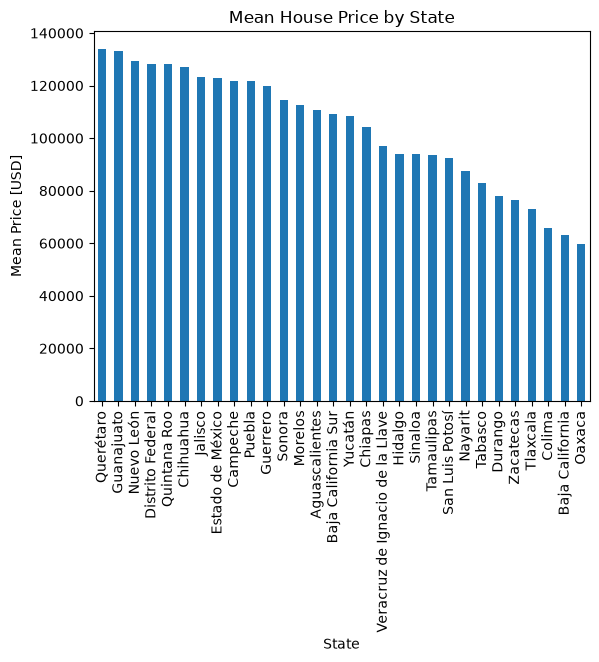

In [12]:
# Aggregate data using groupby
mean_price_by_state = (
    df.groupby("state")["price_usd"]  # <-- "state" & "price_usd"
    .mean()
    .sort_values(ascending=False) # <-- pass in True or False to sort
)

# Create figure and axes explicitly
fig, ax = plt.subplots()

# Use pandas plot method with explicit axes
mean_price_by_state.plot(
    kind="bar",
    ax=ax  # Pass the axes to pandas
)

# Customize using Matplotlib methods
ax.set_xlabel("State")
ax.set_ylabel("Mean Price [USD]")
ax.set_title("Mean House Price by State")

plt.show()

> 📊 **Reading the bar chart — price hierarchy across states**
>
> The bar chart show Distrito Federal with the tallest bar (highest mean
> price), with other states arranged from highest to lowest. This confirms the
> location effect: geography matters.

#### 5.2 Small Multiples: Size vs Price by Location
Now that we know which states are most expensive overall, let's examine whether the relationship between size and price is consistent across locations. This is a fundamentally different question from "which state is expensive?" — it is asking "does size explain price equally well everywhere?"

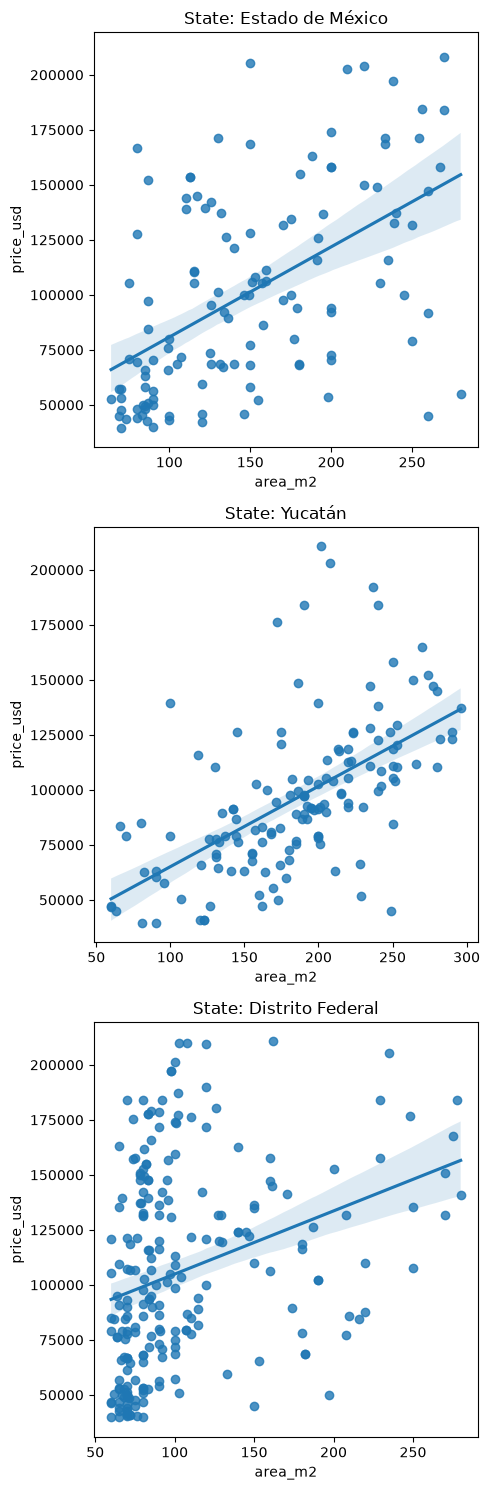

In [13]:
# 1. Create your custom figure and axes
fig, axes = plt.subplots(3, 1, figsize=(5, 15), sharey=True)

# 2. Create a list of the top 3 states
top_states = selected_states  # uses the top 3 states list created earlier

# 3. Filter df_clean to include only these states
df_states = df_clean[df_clean["state"].isin(top_states)]

# 4. Loop through the states and plot on each specific axis
states = df_states["state"].unique()

for ax, state in zip(axes, states):
    # Filter data for the current state
    subset = df_states[df_states["state"] == state]

    # Plot using Seaborn regplot
    sns.regplot(
        data=subset,
        x="area_m2",
        y="price_usd",
        color="tab:blue",
        ax=ax
    )
    ax.set_title(f"State: {state}")

plt.tight_layout()
plt.show()

> 📊 **Reading the small multiples — how location changes the size-price relationship**
>
> Three plots, same two variables, three very different stories:

**Estado de México — moderate positive relationship:**

- The regression line rises at a clear angle — area does predict price here.
- Wide confidence band — the relationship is real but imprecise. Many properties
  deviate substantially from the line.
- Several high-price properties sit well above the line, suggesting other factors
  (proximity to Mexico City? Specific neighborhoods?) drive premiums.

**Yucatán — strongest and most consistent relationship:**

- Narrow confidence band — the regression line is estimated with high precision.
  The relationship between size and price is more predictable here than in the
  other two states.
- Points cluster more tightly around the line.
- Interpretation: in Yucatán, size is a stronger predictor of price than elsewhere.

**Distrito Federal — weakest relationship:**

- Notice the **compression on the x-axis** — most properties cluster between
  60–120 m². In Mexico City, land is expensive and apartments dominate, so large
  properties are genuinely rare.
- The regression line is nearly flat, and the confidence band is wide — size
  barely explains price in Distrito Federal.
- Interpretation: in Mexico City, **price depends more on location within the city
  (neighborhood, floor, view, proximity to transit) than on raw size.** A 100 m²
  apartment in Polanco is worth far more than a 100 m² apartment in the periphery.

> 💡 **The confidence band width is as important as the slope:**
>
> | Observation | Implication |
> |---|---|
> | **Steep slope + narrow band** | Strong, reliable size-price relationship |
> | **Steep slope + wide band** | Size predicts direction but not magnitude precisely |
> | **Flat slope + wide band** | Size barely explains price — other factors dominate |
>
> Distrito Federal falls into the third category. This is the most important result
> of this lesson: **location changes not just the price level, but how well size
> predicts price.**

> 🧠 **Key insight connecting to Lesson 3:**
>
> A single correlation coefficient computed on the *entire* dataset merges three
> very different relationships into one number. In Yucatán, size-price correlation
> might be 0.75. In Distrito Federal, it might be 0.30. The national average could
> be 0.55 — a number that describes *neither* market accurately. This is an example
> of **Simpson's Paradox** (or more precisely, **ecological fallacy**), which we
> will study formally in Lesson 3 when we compute segmented correlations.

**The confidence band as a sample-size signal**

Beyond indicating slope uncertainty, the width of the confidence band carries
a second message: it tells you how much data supports the estimate at each
point along the x-axis. Understanding this turns the band from a decorative
shading into a diagnostic tool.

**Why the band widens at the extremes:** The regression line is fitted to all
the data simultaneously, so it is most precisely estimated where the data is
densest. In our three-state plot:
- For Yucatán and Estado de México, most properties cluster between 60–150 m².
  The band is narrowest in this range — many data points are constraining the
  line's position.
- As area increases toward 200–250 m², fewer properties exist. With fewer points
  to anchor the line, the model becomes less certain about where the line should
  sit. The band widens to communicate this uncertainty honestly.
- At the far right edge of each plot, the band may be extremely wide — there
  could be just one or two properties at those sizes. A single property at 300 m²
  can drag the line significantly, but the wide band tells you not to trust that
  estimate.

**Practical reading rules for the confidence band:**

| Band width | Interpretation | Action |
|---|---|---|
| **Narrow throughout** | Consistent data density; reliable relationship | Trust the slope; report it with confidence |
| **Wide at the edges, narrow in the center** | Normal pattern; dense center, sparse tails | Focus interpretation on the central range |
| **Wide throughout** | Too few data points overall | Report the slope cautiously; get more data |
| **Wider in one state than another (same x-range)** | Fewer listings in that state | Compare listing counts before comparing slopes |

**For Distrito Federal specifically:** the nearly flat line with a wide band is
not just telling you the slope is near zero — it is telling you that the few
large properties in DF are scattered wildly in price, giving the model almost
no information about whether size matters there. The flat slope and the wide band
reinforce each other: size doesn't seem to matter, and we don't have enough data
to be sure either way.
